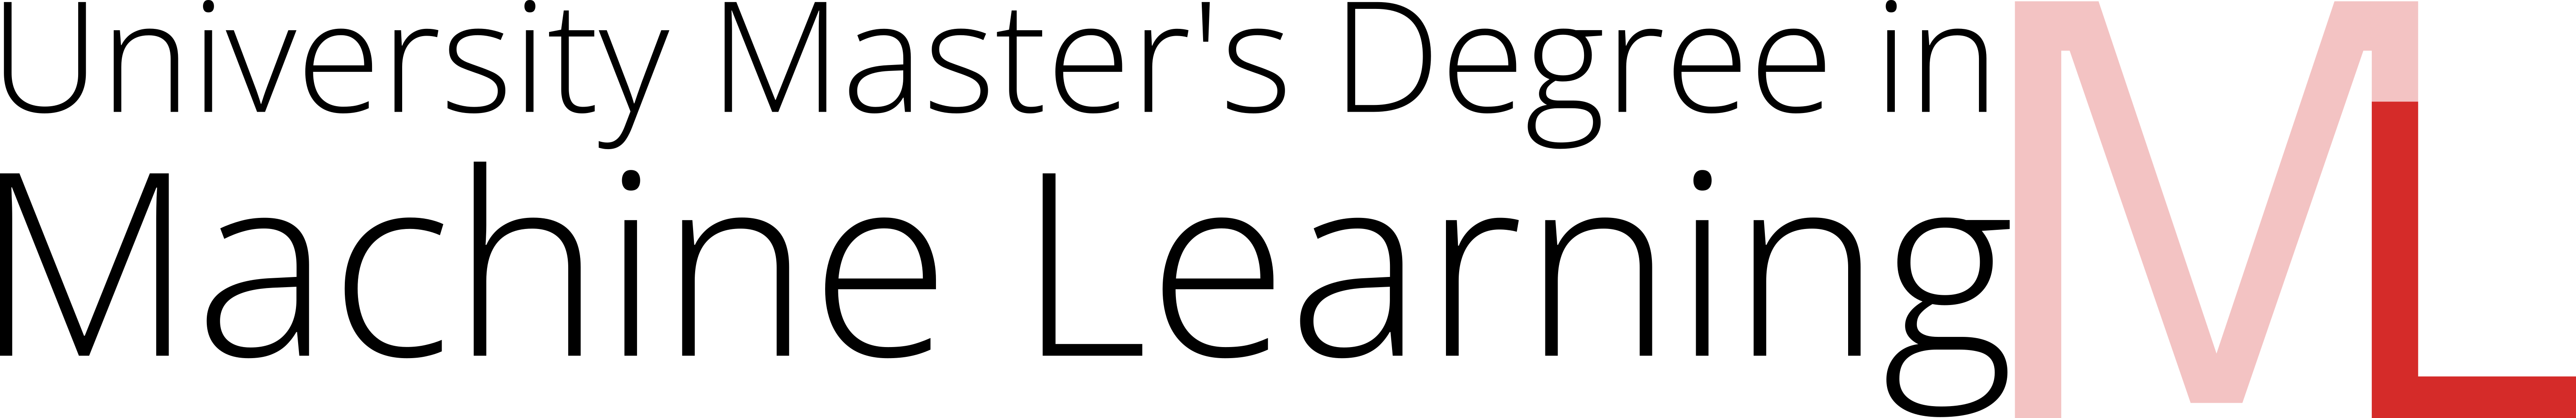

In addition to weight decay and early stopping, Dropout is one of the most useful techniques in fully connected layers (such as those in neural networks), where the large number of connections can lead to overfitting.

To simulate this, we will first implement an MLP class that receives as input parameters in the constructor the number of features/dimensions of the problem, a list with the number of neurons in the hidden layers, and the number of classes. Use `nn.Linear` to create the layers of the network. Then, generate a training loop and train a model with 3 hidden layers of 256 neurons each. Train the model using only 1000 training samples for 5000 iterations with a learning rate of 0.1.





In [1]:
import torch.nn as nn
import torch
import torch.optim as optim
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
import numpy as np

fashion_mnist = torch.load('fashion_mnist.pt')
X_train = fashion_mnist['X_train']
y_train = fashion_mnist['y_train']
X_test = fashion_mnist['X_test']
y_test = fashion_mnist['y_test']

In [2]:
class MLP(nn.Module):
    ##
    def __init__(self, input_size=784, number_neurons=[256, 256, 256], output_size=10):
        super(MLP, self).__init__()
        layers = []
        in_dim = input_size

        for h_dim in number_neurons:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.ReLU())
            in_dim = h_dim

        layers.append(nn.Linear(in_dim, output_size))

        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

In [3]:
def train_model(model, X_train, y_train, X_test, y_test, epochs=10, lr=0.1):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    
    # Se añade 'elapsed_time' para guardar la duración total
    history = {
        'train_loss': [], 
        'train_acc': [], 
        'test_loss': [], 
        'test_acc': [],
        'elapsed_time': 0.0
    }

    start_time = time.time()  # Registro del tiempo de inicio

    pbar = tqdm(range(1, epochs + 1), desc="Training model", unit="epoch")

    for epoch in pbar:
        model.train()
        optimizer.zero_grad()
        
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        
        loss.backward()
        optimizer.step()
        
        _, train_preds = torch.max(outputs, dim=1)
        train_acc = (train_preds == y_train).float().mean().item()
        
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = criterion(test_outputs, y_test)
            
            _, test_preds = torch.max(test_outputs, dim=1)
            test_acc = (test_preds == y_test).float().mean().item()
            
        history['train_loss'].append(loss.item())
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss.item())
        history['test_acc'].append(test_acc)
        
        pbar.set_postfix({
            'Train Loss': f"{loss.item():.4f}",
            'Test Loss': f"{test_loss.item():.4f}",
            'Train Acc': f"{train_acc * 100:.1f}%",
            'Test Acc': f"{test_acc * 100:.1f}%"
        })

    end_time = time.time()
    history['elapsed_time'] = end_time - start_time
    
    print(f"\nTraining completed in {history['elapsed_time']:.2f} seconds.")

    return history

In [4]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

##
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
mlp = MLP(28*28, [256, 256, 256], 10).to(device)
X_train = X_train.to(device)
y_train = y_train.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

history = train_model(
    model=mlp, 
    X_train=X_train[:1000], 
    y_train=y_train[:1000], 
    X_test=X_test, 
    y_test=y_test, 
    epochs=5000, 
    lr=0.1
)


Training model: 100%|██████████████████████████████████████████████████████████████████████| 5000/5000 [00:13<00:00, 363.98epoch/s, Train Loss=0.0005, Test Loss=1.5976, Train Acc=100.0%, Test Acc=79.5%]


Training completed in 13.74 seconds.


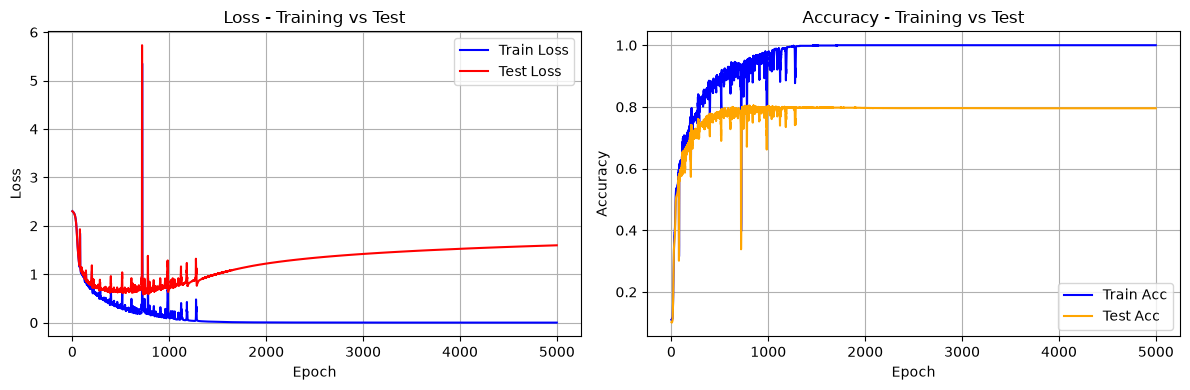

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history['train_loss'], label='Train Loss', color='blue')
ax1.plot(history['test_loss'], label='Test Loss', color='red')
ax1.set_title('Loss - Training vs Test')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(history['train_acc'], label='Train Acc', color='blue')
ax2.plot(history['test_acc'], label='Test Acc', color='orange')
ax2.set_title('Accuracy - Training vs Test')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

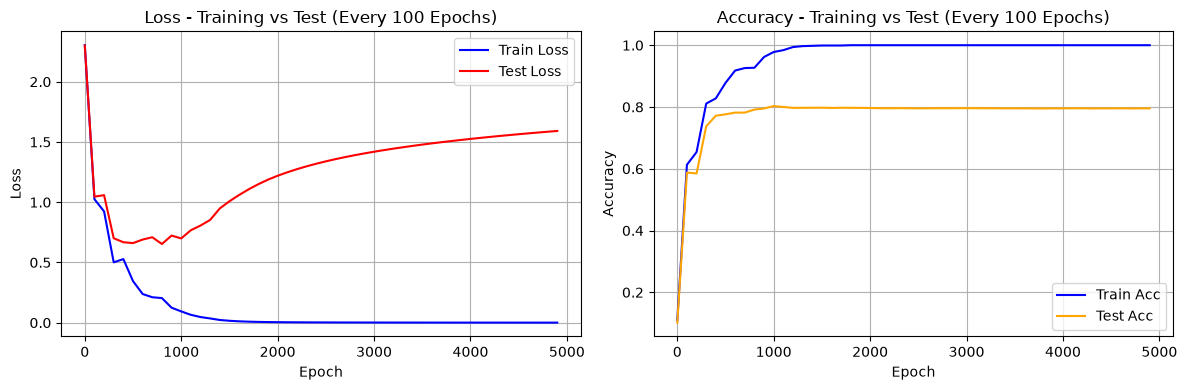

In [6]:
step = 100
epochs_range = range(0, len(history['train_loss']), step)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss Plot
ax1.plot(epochs_range, history['train_loss'][::step], label='Train Loss', color='blue')
ax1.plot(epochs_range, history['test_loss'][::step], label='Test Loss', color='red')
ax1.set_title('Loss - Training vs Test (Every 100 Epochs)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Accuracy Plot
ax2.plot(epochs_range, history['train_acc'][::step], label='Train Acc', color='blue')
ax2.plot(epochs_range, history['test_acc'][::step], label='Test Acc', color='orange')
ax2.set_title('Accuracy - Training vs Test (Every 100 Epochs)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

Observe the behavior of the training loss and test loss as the number of iterations increases.

Now, let’s implement a dropout layer **from scratch**. Create the class **MyDropout** with the following specifications:

* ****init****: takes the dropout probability as an input parameter. Also, initialize a parameter `self.training` (set to `True`) to indicate whether the layer is in training or evaluation mode.
* **forward**: takes `X` and generates a random mask of 0’s and 1’s (with probability `p` of being 0 and `1-p` of being 1). Multiply the input by this mask and, if in training mode, perform rescaling to maintain the expected value.
* **train**: sets `self.training = True`.
* **eval**: sets `self.training = False`.


In [7]:
class MyDropout(nn.Module):
  ##
    def __init__(self, p=0.5):
        super(MyDropout, self).__init__()
        self.p = p
        self.training = True

    def forward(self, X):
        if self.training and self.p > 0.0:
            mask = (torch.rand_like(X) >= self.p).float()
            return (X * mask) / (1.0 - self.p)
        return X

    def train(self, mode=True):
        self.training = mode
        return self

    def eval(self):
        self.training = False
        return self


Check the layer works properly.


In [8]:
X = torch.randn(3, 3)
dropout = MyDropout(0.5)
dropout.train()
print(dropout(X), X.mean())
dropout.eval()
print(dropout(X), X.mean())

tensor([[-0.0000, 4.5604, 0.0877],
        [0.0000, -0.0000, -0.0000],
        [-0.0000, 0.0000, -0.0000]]) tensor(-0.0244)
tensor([[-0.2718,  2.2802,  0.0438],
        [ 0.0996, -0.7271, -0.6763],
        [-0.9672,  0.0726, -0.0737]]) tensor(-0.0244)


Once implemented, create a new MLPWithDO class that incorporates the **MyDropout** layer after each hidden layer. Add two new methods, **train** and **eval**, that calls the `train` and `eval` method of all `MyDropout` layers . Also, modify the training loop to alternate between training and evaluation modes.

Repeat the training using the same hyperparameters, but now with a dropout probability of **0.25**. Finally, compare the results with those obtained previously (without dropout), analyzing differences in training loss, test loss, and generalization. Test other probabilities.


In [9]:
class MLPWithDO(nn.Module):
    ##
    def __init__(self, input_size=784, number_neurons=[256, 256, 256], output_size=10, p=0.25):
        super(MLPWithDO, self).__init__()
        
        self.dropout_layers = []
        layers = []
        in_dim = input_size
        
        for h_dim in number_neurons:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.ReLU())
            
            do_layer = MyDropout(p=p)
            layers.append(do_layer)
            self.dropout_layers.append(do_layer)
            
            in_dim = h_dim
            
        layers.append(nn.Linear(in_dim, output_size))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

    def train(self, mode=True):
        super(MLPWithDO, self).train(mode)
        for layer in self.dropout_layers:
            layer.train(mode)
        return self

    def eval(self):
        super(MLPWithDO, self).eval()
        for layer in self.dropout_layers:
            layer.eval()
        return self

In [10]:
def train_model(model, X_train, y_train, X_test, y_test, epochs=10, lr = 0.1):
    ##
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    
    # Historial de métricas y tiempo de ejecución
    history = {
        'train_loss': [], 
        'train_acc': [], 
        'test_loss': [], 
        'test_acc': [],
        'elapsed_time': 0.0
    }

    start_time = time.time()
    pbar = tqdm(range(1, epochs + 1), desc="Training model", unit="epoch")

    for epoch in pbar:
        model.train()
        optimizer.zero_grad()
        
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        
        loss.backward()
        optimizer.step()
        
        _, train_preds = torch.max(outputs, dim=1)
        train_acc = (train_preds == y_train).float().mean().item()
        
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = criterion(test_outputs, y_test)
            
            _, test_preds = torch.max(test_outputs, dim=1)
            test_acc = (test_preds == y_test).float().mean().item()
            
        history['train_loss'].append(loss.item())
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss.item())
        history['test_acc'].append(test_acc)
        
        pbar.set_postfix({
            'Tr Loss': f"{loss.item():.4f}",
            'Te Loss': f"{test_loss.item():.4f}",
            'Tr Acc': f"{train_acc * 100:.1f}%",
            'Te Acc': f"{test_acc * 100:.1f}%"
        })

    end_time = time.time()
    history['elapsed_time'] = end_time - start_time
    print(f"\nTraining completed in {history['elapsed_time']:.2f} seconds.")

    return history

In [11]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
##
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

mlp = MLPWithDO(28*28, [256, 256, 256], 10, 0.25).to(device)


history_do = train_model(
    model=mlp,
    X_train=X_train[:1000],
    y_train=y_train[:1000],
    X_test=X_test,
    y_test=y_test,
    epochs=5000,
    lr=0.1
)

Training model: 100%|█████████████████████████████████████████████████████████████████████████████████| 5000/5000 [00:15<00:00, 331.04epoch/s, Tr Loss=0.0023, Te Loss=1.4711, Tr Acc=99.9%, Te Acc=79.8%]


Training completed in 15.11 seconds.


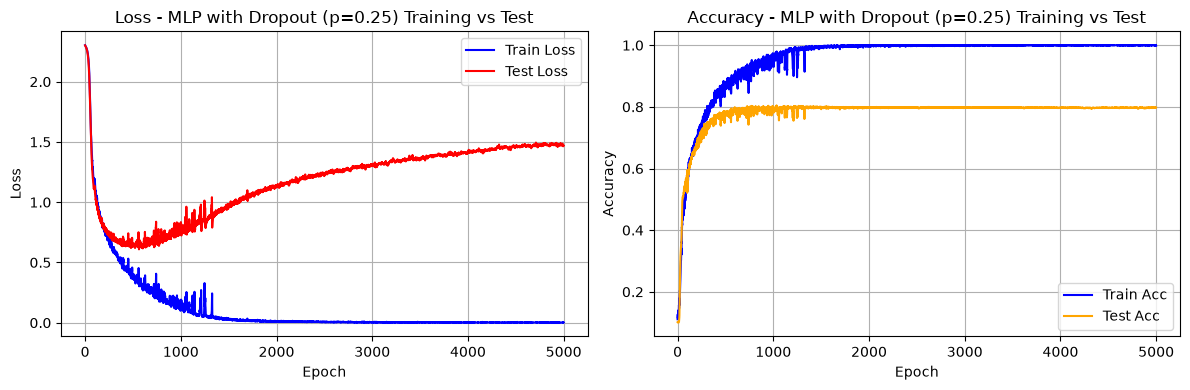

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history_do['train_loss'], label='Train Loss', color='blue')
ax1.plot(history_do['test_loss'], label='Test Loss', color='red')
ax1.set_title('Loss - MLP with Dropout (p=0.25) Training vs Test')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(history_do['train_acc'], label='Train Acc', color='blue')
ax2.plot(history_do['test_acc'], label='Test Acc', color='orange')
ax2.set_title('Accuracy - MLP with Dropout (p=0.25) Training vs Test')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

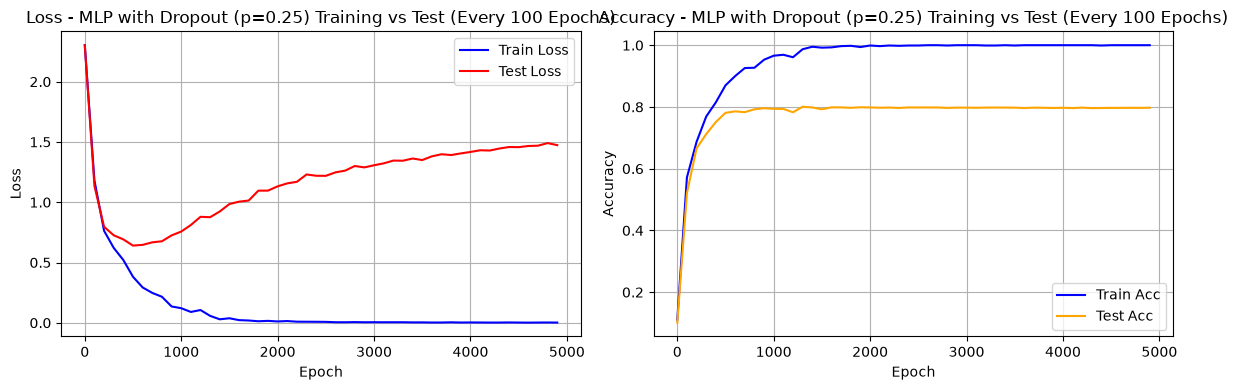

In [13]:
step = 100
epochs_range = range(0, len(history['train_loss']), step)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss Plot
ax1.plot(epochs_range, history_do['train_loss'][::step], label='Train Loss', color='blue')
ax1.plot(epochs_range, history_do['test_loss'][::step], label='Test Loss', color='red')
ax1.set_title('Loss - MLP with Dropout (p=0.25) Training vs Test (Every 100 Epochs)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Accuracy Plot
ax2.plot(epochs_range, history_do['train_acc'][::step], label='Train Acc', color='blue')
ax2.plot(epochs_range, history_do['test_acc'][::step], label='Test Acc', color='orange')
ax2.set_title('Accuracy - MLP with Dropout (p=0.25) Training vs Test (Every 100 Epochs)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### Assignment

Based on the assignment from the notebook **05\_MLP\_4**, extend your study by incorporating the regularization techniques covered in class. Analyze how these techniques affect:

* **Model convergence** (training speed and stability).
* **Generalization ability** (performance on unseen data).
* **Overfitting reduction** (gap between training and test error).

Include comparisons between models trained **without regularization** and models trained with techniques such as **weight decay, early stopping, and dropout**.


In [22]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# Estilo visual para las gráficas
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# ==============================================================================
# 1. CARGA DE DATOS Y DEFINICIÓN DE COMPONENTES
# ==============================================================================
fashion_mnist = torch.load('fashion_mnist.pt')
X_train_full = fashion_mnist['X_train']
y_train_full = fashion_mnist['y_train']
X_test = fashion_mnist['X_test']
y_test = fashion_mnist['y_test']

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Restricción a 1000 muestras de entrenamiento
X_train = X_train_full.to(device)
y_train = y_train_full.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

class MyDropout(nn.Module):
    def __init__(self, p=0.5):
        super(MyDropout, self).__init__()
        self.p = p
        self.training = True

    def forward(self, X):
        if self.training and self.p > 0.0:
            mask = (torch.rand_like(X) >= self.p).float()
            return (X * mask) / (1.0 - self.p)
        return X

    def train(self, mode=True):
        self.training = mode
        return self

    def eval(self):
        self.training = False
        return self

class RegularizedMLP(nn.Module):
    def __init__(self, input_size=784, hidden_units=[256, 256, 256], output_size=10, dropout_p=0.0):
        super(RegularizedMLP, self).__init__()
        self.dropout_layers = []
        layers = []
        in_dim = input_size

        for h_dim in hidden_units:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.ReLU())
            if dropout_p > 0.0:
                do_layer = MyDropout(p=dropout_p)
                layers.append(do_layer)
                self.dropout_layers.append(do_layer)
            in_dim = h_dim

        layers.append(nn.Linear(in_dim, output_size))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

    def train(self, mode=True):
        super(RegularizedMLP, self).train(mode)
        for layer in self.dropout_layers:
            layer.train(mode)
        return self

    def eval(self):
        super(RegularizedMLP, self).eval()
        for layer in self.dropout_layers:
            layer.eval()
        return self

def train_experiment(model, X_train, y_train, X_test, y_test, 
                     epochs=5000, lr=0.1, weight_decay=0.0, use_early_stopping=False, patience=300):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {
        'train_loss': [], 'train_acc': [],
        'test_loss': [], 'test_acc': [],
        'stopped_epoch': epochs,
        'elapsed_time': 0.0
    }

    best_test_loss = float('inf')
    patience_counter = 0

    start_time = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        loss.backward()
        optimizer.step()

        _, train_preds = torch.max(outputs, dim=1)
        train_acc = (train_preds == y_train).float().mean().item()

        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = criterion(test_outputs, y_test)
            _, test_preds = torch.max(test_outputs, dim=1)
            test_acc = (test_preds == y_test).float().mean().item()

        history['train_loss'].append(loss.item())
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss.item())
        history['test_acc'].append(test_acc)

        if use_early_stopping:
            if test_loss.item() < best_test_loss:
                best_test_loss = test_loss.item()
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    history['stopped_epoch'] = epoch
                    break

    history['elapsed_time'] = time.time() - start_time
    return history

# ==============================================================================
# 2. BUCLE UNIFICADO DE ENTRENAMIENTO DE EXPERIMENTOS
# ==============================================================================
all_configs = {
    # Experimentos Principales
    'Unregularized Baseline': {'p': 0.0, 'wd': 0.0, 'es': False},
    'Dropout (p=0.25)': {'p': 0.25, 'wd': 0.0, 'es': False},
    'Dropout (p=0.50)': {'p': 0.50, 'wd': 0.0, 'es': False},
    'Weight Decay (1e-4)': {'p': 0.0, 'wd': 1e-4, 'es': False},
    'Early Stopping': {'p': 0.0, 'wd': 0.0, 'es': True},
    'Combined (DO 0.25 + WD 1e-4 + ES)': {'p': 0.25, 'wd': 1e-4, 'es': True},
    
    # Sweep de Weight Decay
    'WD (1e-5)': {'p': 0.0, 'wd': 1e-5, 'es': False},
    'WD (1e-3)': {'p': 0.0, 'wd': 1e-3, 'es': False},
    'WD (1e-2)': {'p': 0.0, 'wd': 1e-2, 'es': False},
    'WD (1e-1)': {'p': 0.0, 'wd': 1e-1, 'es': False},

    # Sweep de Dropout
    'Dropout (0.1)': {'p': 0.1, 'wd': 0.0, 'es': False},
    'Dropout (0.2)': {'p': 0.2, 'wd': 0.0, 'es': False},
    'Dropout (0.3)': {'p': 0.3, 'wd': 0.0, 'es': False},
    'Dropout (0.4)': {'p': 0.4, 'wd': 0.0, 'es': False},
    'Dropout (0.6)': {'p': 0.6, 'wd': 0.0, 'es': False},
    'Dropout (0.7)': {'p': 0.7, 'wd': 0.0, 'es': False},
}

all_results = {}

print("=================================================================")
print("             EJECUTANDO BUCLE CENTRAL DE ENTRENAMIENTO            ")
print("=================================================================")

for name, cfg in all_configs.items():
    print(f"Entrenando modelo: {name:<35} | ", end="")
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(42)
        
    model = RegularizedMLP(dropout_p=cfg['p']).to(device)
    hist = train_experiment(
        model, X_train, y_train, X_test, y_test,
        epochs=5000, lr=0.1, weight_decay=cfg['wd'], use_early_stopping=cfg['es']
    )
    all_results[name] = hist
    
    tr_acc = hist['train_acc'][-1] * 100
    te_acc = hist['test_acc'][-1] * 100
    gap = tr_acc - te_acc
    print(f"Tr Acc: {tr_acc:5.2f}% | Te Acc: {te_acc:5.2f}% | Gap: {gap:5.2f}% | Time: {hist['elapsed_time']:5.2f}s")

def print_table(title, keys):
    print("\n" + "=" * 90)
    print(f" RESULTS TABLE: {title.upper()}")
    print("=" * 90)
    print(f"{'Model / Strategy':<38} | {'Train Acc':<10} | {'Test Acc':<10} | {'Gap':<8} | {'Time (s)':<10} | {'Stop Epoch'}")
    print("-" * 90)
    for k in keys:
        h = all_results[k]
        tr_acc = h['train_acc'][-1] * 100
        te_acc = h['test_acc'][-1] * 100
        gap = tr_acc - te_acc
        print(f"{k:<38} | {tr_acc:6.2f}%    | {te_acc:6.2f}%    | {gap:5.2f}%  | {h['elapsed_time']:8.2f}s  | {h['stopped_epoch']}")
    print("=" * 90)

             EJECUTANDO BUCLE CENTRAL DE ENTRENAMIENTO            
Entrenando modelo: Unregularized Baseline              | Tr Acc: 91.75% | Te Acc: 87.78% | Gap:  3.97% | Time: 18.89s
Entrenando modelo: Dropout (p=0.25)                    | Tr Acc: 90.73% | Te Acc: 88.35% | Gap:  2.38% | Time: 23.77s
Entrenando modelo: Dropout (p=0.50)                    | Tr Acc: 89.26% | Te Acc: 87.84% | Gap:  1.42% | Time: 23.57s
Entrenando modelo: Weight Decay (1e-4)                 | Tr Acc: 91.31% | Te Acc: 88.41% | Gap:  2.90% | Time: 19.43s
Entrenando modelo: Early Stopping                      | Tr Acc: 89.88% | Te Acc: 87.03% | Gap:  2.85% | Time: 16.98s
Entrenando modelo: Combined (DO 0.25 + WD 1e-4 + ES)   | Tr Acc: 90.53% | Te Acc: 88.36% | Gap:  2.17% | Time: 24.18s
Entrenando modelo: WD (1e-5)                           | Tr Acc: 91.43% | Te Acc: 88.18% | Gap:  3.25% | Time: 19.19s
Entrenando modelo: WD (1e-3)                           | Tr Acc: 89.63% | Te Acc: 87.17% | Gap:  2.46% | Ti

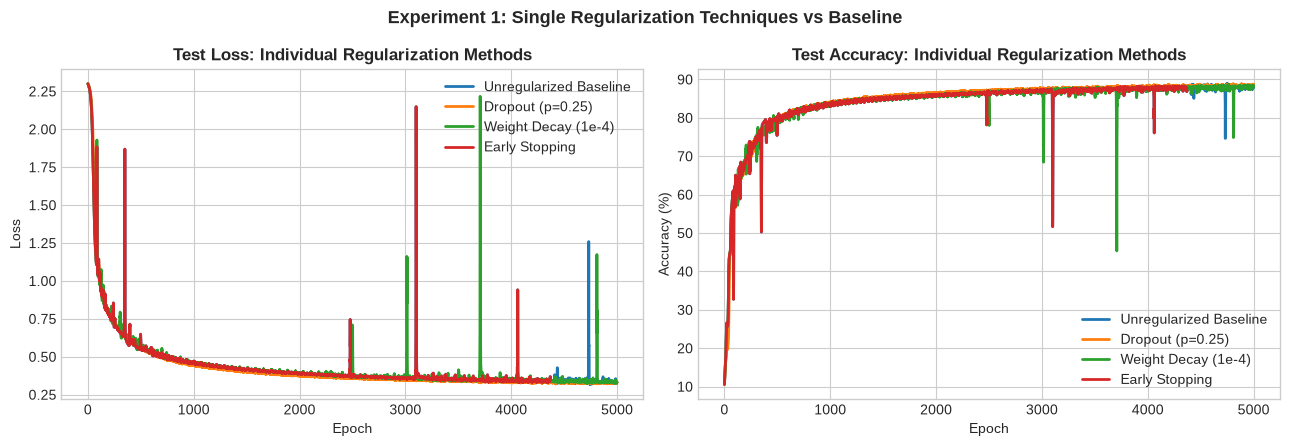


 RESULTS TABLE: EXPERIMENT 1: SINGLE TECHNIQUES COMPARISON
Model / Strategy                       | Train Acc  | Test Acc   | Gap      | Time (s)   | Stop Epoch
------------------------------------------------------------------------------------------
Unregularized Baseline                 |  91.75%    |  87.78%    |  3.97%  |    18.89s  | 5000
Dropout (p=0.25)                       |  90.73%    |  88.35%    |  2.38%  |    23.77s  | 5000
Weight Decay (1e-4)                    |  91.31%    |  88.41%    |  2.90%  |    19.43s  | 5000
Early Stopping                         |  89.88%    |  87.03%    |  2.85%  |    16.98s  | 4372


In [23]:
keys_exp1 = ['Unregularized Baseline', 'Dropout (p=0.25)', 'Weight Decay (1e-4)', 'Early Stopping']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for k in keys_exp1:
    ax1.plot(all_results[k]['test_loss'], label=k, linewidth=2)
    ax2.plot(np.array(all_results[k]['test_acc']) * 100, label=k, linewidth=2)

ax1.set_title('Test Loss: Individual Regularization Methods', fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss'); ax1.legend(); ax1.grid(True)

ax2.set_title('Test Accuracy: Individual Regularization Methods', fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)'); ax2.legend(); ax2.grid(True)

plt.suptitle('Experiment 1: Single Regularization Techniques vs Baseline', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print_table("Experiment 1: Single Techniques Comparison", keys_exp1)

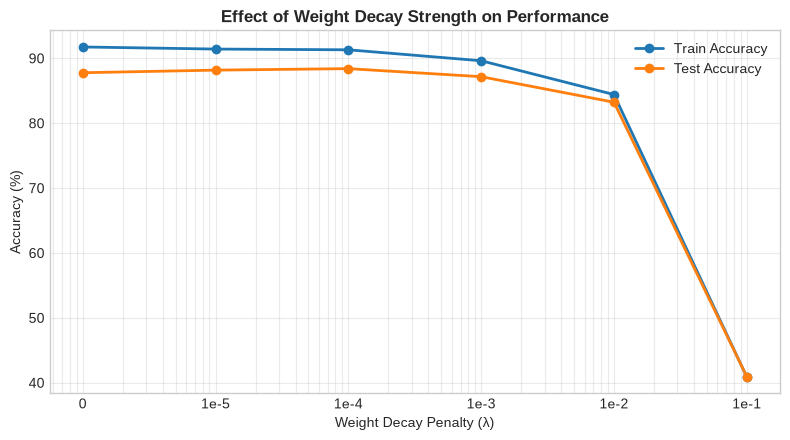


 RESULTS TABLE: EXPERIMENT 3: WEIGHT DECAY SWEEP
Model / Strategy                       | Train Acc  | Test Acc   | Gap      | Time (s)   | Stop Epoch
------------------------------------------------------------------------------------------
Unregularized Baseline                 |  91.75%    |  87.78%    |  3.97%  |    18.89s  | 5000
WD (1e-5)                              |  91.43%    |  88.18%    |  3.25%  |    19.19s  | 5000
Weight Decay (1e-4)                    |  91.31%    |  88.41%    |  2.90%  |    19.43s  | 5000
WD (1e-3)                              |  89.63%    |  87.17%    |  2.46%  |    19.26s  | 5000
WD (1e-2)                              |  84.42%    |  83.23%    |  1.18%  |    19.30s  | 5000
WD (1e-1)                              |  40.89%    |  40.93%    | -0.04%  |    19.31s  | 5000


In [24]:
wd_keys = ['Unregularized Baseline', 'WD (1e-5)', 'Weight Decay (1e-4)', 'WD (1e-3)', 'WD (1e-2)', 'WD (1e-1)']
wd_vals = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1] # 1e-6 representa el 0.0 para escala logarítmica

tr_acc_wd = [all_results[k]['train_acc'][-1] * 100 for k in wd_keys]
te_acc_wd = [all_results[k]['test_acc'][-1] * 100 for k in wd_keys]

plt.figure(figsize=(8, 4.5))
plt.plot(wd_vals, tr_acc_wd, marker='o', label='Train Accuracy', linewidth=2)
plt.plot(wd_vals, te_acc_wd, marker='o', label='Test Accuracy', linewidth=2)
plt.xscale('log')
plt.xticks(wd_vals, ['0', '1e-5', '1e-4', '1e-3', '1e-2', '1e-1'])
plt.xlabel('Weight Decay Penalty (λ)'); plt.ylabel('Accuracy (%)')
plt.title('Effect of Weight Decay Strength on Performance', fontweight='bold')
plt.grid(True, which='both', alpha=0.4); plt.legend()
plt.tight_layout()
plt.show()

print_table("Experiment 3: Weight Decay Sweep", wd_keys)

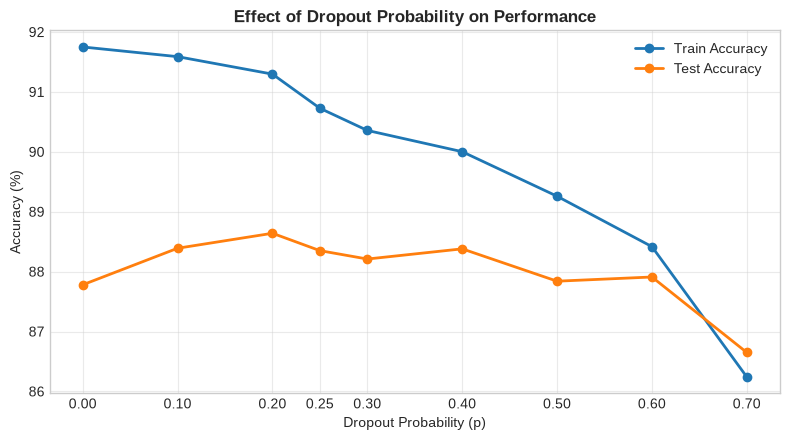


 RESULTS TABLE: EXPERIMENT 4: DROPOUT INTENSITY SWEEP
Model / Strategy                       | Train Acc  | Test Acc   | Gap      | Time (s)   | Stop Epoch
------------------------------------------------------------------------------------------
Unregularized Baseline                 |  91.75%    |  87.78%    |  3.97%  |    18.89s  | 5000
Dropout (0.1)                          |  91.59%    |  88.39%    |  3.20%  |    24.02s  | 5000
Dropout (0.2)                          |  91.30%    |  88.64%    |  2.66%  |    24.12s  | 5000
Dropout (p=0.25)                       |  90.73%    |  88.35%    |  2.38%  |    23.77s  | 5000
Dropout (0.3)                          |  90.36%    |  88.21%    |  2.15%  |    23.95s  | 5000
Dropout (0.4)                          |  90.00%    |  88.38%    |  1.62%  |    23.89s  | 5000
Dropout (p=0.50)                       |  89.26%    |  87.84%    |  1.42%  |    23.57s  | 5000
Dropout (0.6)                          |  88.42%    |  87.91%    |  0.51%  |    23.76s 

In [25]:
do_keys = ['Unregularized Baseline', 'Dropout (0.1)', 'Dropout (0.2)', 'Dropout (p=0.25)', 
           'Dropout (0.3)', 'Dropout (0.4)', 'Dropout (p=0.50)', 'Dropout (0.6)', 'Dropout (0.7)']
do_probs = [0.0, 0.1, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7]

tr_acc_do = [all_results[k]['train_acc'][-1] * 100 for k in do_keys]
te_acc_do = [all_results[k]['test_acc'][-1] * 100 for k in do_keys]

plt.figure(figsize=(8, 4.5))
plt.plot(do_probs, tr_acc_do, marker='o', label='Train Accuracy', linewidth=2)
plt.plot(do_probs, te_acc_do, marker='o', label='Test Accuracy', linewidth=2)
plt.xticks(do_probs)
plt.xlabel('Dropout Probability (p)'); plt.ylabel('Accuracy (%)')
plt.title('Effect of Dropout Probability on Performance', fontweight='bold')
plt.grid(True, alpha=0.4); plt.legend()
plt.tight_layout()
plt.show()

print_table("Experiment 4: Dropout Intensity Sweep", do_keys)

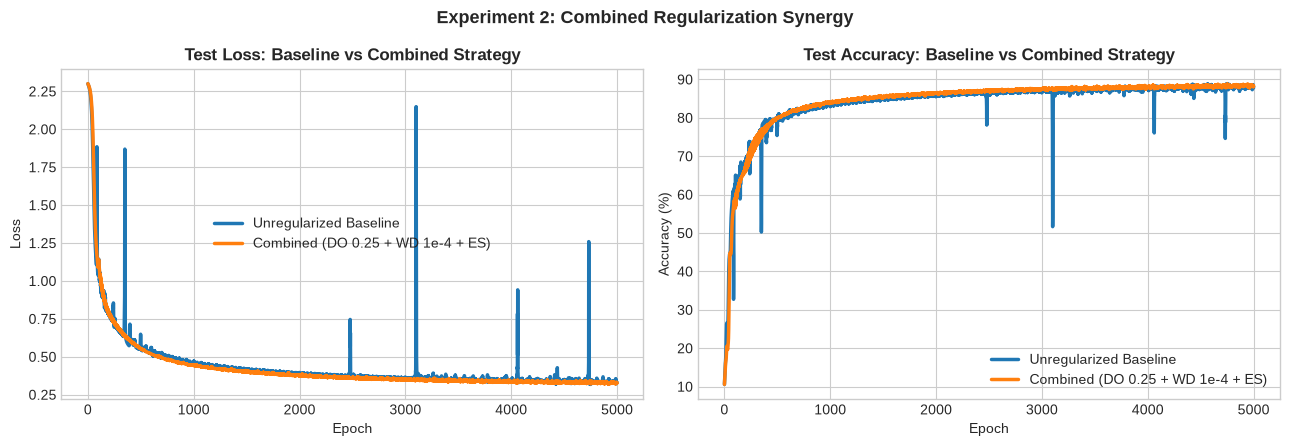


 RESULTS TABLE: EXPERIMENT 2: COMBINED REGULARIZATION SYNERGY
Model / Strategy                       | Train Acc  | Test Acc   | Gap      | Time (s)   | Stop Epoch
------------------------------------------------------------------------------------------
Unregularized Baseline                 |  91.75%    |  87.78%    |  3.97%  |    18.89s  | 5000
Combined (DO 0.25 + WD 1e-4 + ES)      |  90.53%    |  88.36%    |  2.17%  |    24.18s  | 5000


In [26]:
keys_exp2 = ['Unregularized Baseline', 'Combined (DO 0.25 + WD 1e-4 + ES)']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for k in keys_exp2:
    ax1.plot(all_results[k]['test_loss'], label=k, linewidth=2.5)
    ax2.plot(np.array(all_results[k]['test_acc']) * 100, label=k, linewidth=2.5)

ax1.set_title('Test Loss: Baseline vs Combined Strategy', fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss'); ax1.legend(); ax1.grid(True)

ax2.set_title('Test Accuracy: Baseline vs Combined Strategy', fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)'); ax2.legend(); ax2.grid(True)

plt.suptitle('Experiment 2: Combined Regularization Synergy', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print_table("Experiment 2: Combined Regularization Synergy", keys_exp2)

In [27]:
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# Estilo visual para las gráficas
plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

# ==============================================================================
# 1. CARGA DE DATOS Y DEFINICIÓN DE COMPONENTES
# ==============================================================================

fashion_mnist = torch.load('fashion_mnist.pt')

X_train_full = fashion_mnist['X_train']
y_train_full = fashion_mnist['y_train']
X_test = fashion_mnist['X_test']
y_test = fashion_mnist['y_test']

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Usamos TODOS los datos de entrenamiento
X_train_full = X_train_full.to(device)
y_train_full = y_train_full.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

print(f"Training samples: {len(X_train_full)}")
print(f"Test samples:     {len(X_test)}")
print(f"Device:            {device}")


# ==============================================================================
# 2. TRAIN / VALIDATION SPLIT
# ==============================================================================

# 90% training / 10% validation
validation_ratio = 0.10

n_samples = len(X_train_full)
n_validation = int(n_samples * validation_ratio)

# Shuffle once before splitting
split_generator = torch.Generator(device=device)
split_generator.manual_seed(2026)

indices = torch.randperm(n_samples, generator=split_generator, device=device)

val_indices = indices[:n_validation]
train_indices = indices[n_validation:]

X_train = X_train_full[train_indices]
y_train = y_train_full[train_indices]

X_val = X_train_full[val_indices]
y_val = y_train_full[val_indices]

print(f"Training samples:   {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"Test samples:       {len(X_test)}")


# ==============================================================================
# 3. CUSTOM DROPOUT
# ==============================================================================

class MyDropout(nn.Module):

    def __init__(self, p=0.5):
        super(MyDropout, self).__init__()
        self.p = p
        self.training = True

    def forward(self, X):

        if self.training and self.p > 0.0:

            mask = (torch.rand_like(X) >= self.p).float()

            return (X * mask) / (1.0 - self.p)

        return X

    def train(self, mode=True):

        self.training = mode

        return self

    def eval(self):

        self.training = False

        return self


# ==============================================================================
# 4. MODEL
# ==============================================================================

class RegularizedMLP(nn.Module):

    def __init__(
        self,
        input_size=784,
        hidden_units=[256, 256, 256],
        output_size=10,
        dropout_p=0.0
    ):

        super(RegularizedMLP, self).__init__()

        self.dropout_layers = []

        layers = []

        in_dim = input_size

        for h_dim in hidden_units:

            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.ReLU())

            if dropout_p > 0.0:

                do_layer = MyDropout(p=dropout_p)

                layers.append(do_layer)

                self.dropout_layers.append(do_layer)

            in_dim = h_dim

        layers.append(nn.Linear(in_dim, output_size))

        self.net = nn.Sequential(*layers)


    def forward(self, x):

        return self.net(x)


    def train(self, mode=True):

        super(RegularizedMLP, self).train(mode)

        for layer in self.dropout_layers:
            layer.train(mode)

        return self


    def eval(self):

        super(RegularizedMLP, self).eval()

        for layer in self.dropout_layers:
            layer.eval()

        return self


# ==============================================================================
# 5. TRAINING FUNCTION
# ==============================================================================

def train_experiment(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    epochs=5000,
    lr=0.1,
    weight_decay=0.0,
    use_early_stopping=False,
    patience=200,
    min_delta=1e-4
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    history = {

        'train_loss': [],
        'train_acc': [],

        'val_loss': [],
        'val_acc': [],

        'test_loss': [],
        'test_acc': [],

        'stopped_epoch': epochs,
        'elapsed_time': 0.0
    }

    best_val_loss = float('inf')
    best_state = None

    patience_counter = 0

    start_time = time.time()


    # --------------------------------------------------------------------------
    # TRAINING LOOP
    # --------------------------------------------------------------------------

    for epoch in range(1, epochs + 1):

        # ======================================================================
        # TRAIN
        # ======================================================================

        model.train()

        optimizer.zero_grad()

        outputs = model(X_train)

        train_loss = criterion(outputs, y_train)

        train_loss.backward()

        optimizer.step()


        # Training accuracy
        _, train_preds = torch.max(outputs, dim=1)

        train_acc = (
            train_preds == y_train
        ).float().mean().item()


        # ======================================================================
        # VALIDATION
        # ======================================================================

        model.eval()

        with torch.no_grad():

            val_outputs = model(X_val)

            val_loss = criterion(
                val_outputs,
                y_val
            )

            _, val_preds = torch.max(
                val_outputs,
                dim=1
            )

            val_acc = (
                val_preds == y_val
            ).float().mean().item()


        # ======================================================================
        # STORE TRAIN / VALIDATION HISTORY
        # ======================================================================

        history['train_loss'].append(
            train_loss.item()
        )

        history['train_acc'].append(
            train_acc
        )

        history['val_loss'].append(
            val_loss.item()
        )

        history['val_acc'].append(
            val_acc
        )


        # ======================================================================
        # EARLY STOPPING
        # ======================================================================

        if use_early_stopping:

            if val_loss.item() < best_val_loss - min_delta:

                best_val_loss = val_loss.item()

                patience_counter = 0

                # Save best model
                best_state = copy.deepcopy(
                    model.state_dict()
                )

            else:

                patience_counter += 1

                if patience_counter >= patience:

                    history['stopped_epoch'] = epoch

                    break


    # ==============================================================================
    # RESTORE BEST MODEL
    # ==============================================================================

    if use_early_stopping and best_state is not None:

        model.load_state_dict(best_state)


    # ==============================================================================
    # FINAL TEST EVALUATION
    # ==============================================================================

    model.eval()

    with torch.no_grad():

        test_outputs = model(X_test)

        test_loss = criterion(
            test_outputs,
            y_test
        )

        _, test_preds = torch.max(
            test_outputs,
            dim=1
        )

        test_acc = (
            test_preds == y_test
        ).float().mean().item()


    # Store final test performance
    history['test_loss'] = [
        test_loss.item()
    ]

    history['test_acc'] = [
        test_acc
    ]

    history['elapsed_time'] = time.time() - start_time


    return history


# ==============================================================================
# 6. EXPERIMENT CONFIGURATIONS
# ==============================================================================

all_configs = {

    # --------------------------------------------------------------------------
    # MAIN EXPERIMENTS
    # --------------------------------------------------------------------------

    'Unregularized Baseline': {
        'p': 0.0,
        'wd': 0.0,
        'es': False
    },

    'Dropout (p=0.25)': {
        'p': 0.25,
        'wd': 0.0,
        'es': False
    },

    'Weight Decay (1e-4)': {
        'p': 0.0,
        'wd': 1e-4,
        'es': False
    },

    'Early Stopping': {
        'p': 0.0,
        'wd': 0.0,
        'es': True
    },

    'Combined (DO 0.25 + WD 1e-4 + ES)': {
        'p': 0.25,
        'wd': 1e-4,
        'es': True
    },


    # --------------------------------------------------------------------------
    # WEIGHT DECAY SWEEP
    # --------------------------------------------------------------------------

    'WD (1e-5)': {
        'p': 0.0,
        'wd': 1e-5,
        'es': False
    },

    'WD (1e-3)': {
        'p': 0.0,
        'wd': 1e-3,
        'es': False
    },

    'WD (1e-2)': {
        'p': 0.0,
        'wd': 1e-2,
        'es': False
    },

    'WD (1e-1)': {
        'p': 0.0,
        'wd': 1e-1,
        'es': False
    },


    # --------------------------------------------------------------------------
    # DROPOUT SWEEP
    # --------------------------------------------------------------------------

    'Dropout (0.1)': {
        'p': 0.1,
        'wd': 0.0,
        'es': False
    },

    'Dropout (0.2)': {
        'p': 0.2,
        'wd': 0.0,
        'es': False
    },

    'Dropout (0.3)': {
        'p': 0.3,
        'wd': 0.0,
        'es': False
    },

    'Dropout (0.4)': {
        'p': 0.4,
        'wd': 0.0,
        'es': False
    },

    'Dropout (0.6)': {
        'p': 0.6,
        'wd': 0.0,
        'es': False
    },

    'Dropout (0.7)': {
        'p': 0.7,
        'wd': 0.0,
        'es': False
    }
}


# ==============================================================================
# 7. RUN ALL EXPERIMENTS
# ==============================================================================

seeds = [42, 100, 2026]

all_results = {}

print()
print("=" * 100)
print("                 RUNNING REGULARIZATION EXPERIMENTS")
print("=" * 100)

for name, cfg in all_configs.items():

    print()
    print(f"Experiment: {name}")

    all_results[name] = []


    for seed in seeds:

        print(
            f"  Seed {seed:<5} | ",
            end=""
        )


        # ----------------------------------------------------------------------
        # Reproducibility
        # ----------------------------------------------------------------------

        torch.manual_seed(seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed(seed)


        # ----------------------------------------------------------------------
        # Model
        # ----------------------------------------------------------------------

        model = RegularizedMLP(
            dropout_p=cfg['p']
        ).to(device)


        # ----------------------------------------------------------------------
        # Training
        # ----------------------------------------------------------------------

        hist = train_experiment(

            model,

            X_train,
            y_train,

            X_val,
            y_val,

            X_test,
            y_test,

            epochs=5000,

            lr=0.1,

            weight_decay=cfg['wd'],

            use_early_stopping=cfg['es'],

            patience=200,

            min_delta=1e-4
        )


        all_results[name].append(hist)


        # ----------------------------------------------------------------------
        # Display result
        # ----------------------------------------------------------------------

        tr_acc = hist['train_acc'][-1] * 100

        val_acc = hist['val_acc'][-1] * 100

        te_acc = hist['test_acc'][-1] * 100

        acc_gap = tr_acc - te_acc

        train_loss = hist['train_loss'][-1]

        val_loss = hist['val_loss'][-1]

        test_loss = hist['test_loss'][-1]

        loss_gap = test_loss - train_loss


        print(
            f"Train: {tr_acc:6.2f}% | "
            f"Val: {val_acc:6.2f}% | "
            f"Test: {te_acc:6.2f}% | "
            f"Acc Gap: {acc_gap:6.2f}% | "
            f"Loss Gap: {loss_gap:7.4f} | "
            f"Epochs: {hist['stopped_epoch']:4d}"
        )


# ==============================================================================
# 8. SUMMARY TABLE
# ==============================================================================

def summarize_results(name):

    results = all_results[name]

    train_accs = [
        h['train_acc'][-1] * 100
        for h in results
    ]

    val_accs = [
        h['val_acc'][-1] * 100
        for h in results
    ]

    test_accs = [
        h['test_acc'][-1] * 100
        for h in results
    ]

    train_losses = [
        h['train_loss'][-1]
        for h in results
    ]

    test_losses = [
        h['test_loss'][-1]
        for h in results
    ]

    acc_gaps = [
        train_accs[i] - test_accs[i]
        for i in range(len(results))
    ]

    loss_gaps = [
        test_losses[i] - train_losses[i]
        for i in range(len(results))
    ]

    epochs = [
        h['stopped_epoch']
        for h in results
    ]

    times = [
        h['elapsed_time']
        for h in results
    ]


    return {

        'train_acc_mean': np.mean(train_accs),
        'train_acc_std': np.std(train_accs),

        'val_acc_mean': np.mean(val_accs),
        'val_acc_std': np.std(val_accs),

        'test_acc_mean': np.mean(test_accs),
        'test_acc_std': np.std(test_accs),

        'train_loss_mean': np.mean(train_losses),

        'test_loss_mean': np.mean(test_losses),

        'acc_gap_mean': np.mean(acc_gaps),

        'loss_gap_mean': np.mean(loss_gaps),

        'epochs_mean': np.mean(epochs),

        'time_mean': np.mean(times)
    }


def print_table(title, keys):

    print()
    print("=" * 130)
    print(f"RESULTS TABLE: {title.upper()}")
    print("=" * 130)

    print(
        f"{'Model / Strategy':<38} | "
        f"{'Train Acc':<15} | "
        f"{'Val Acc':<15} | "
        f"{'Test Acc':<15} | "
        f"{'Acc Gap':<10} | "
        f"{'Loss Gap':<10} | "
        f"{'Epochs':<8}"
    )

    print("-" * 130)


    for k in keys:

        s = summarize_results(k)

        print(
            f"{k:<38} | "
            f"{s['train_acc_mean']:6.2f} ± {s['train_acc_std']:.2f} | "
            f"{s['val_acc_mean']:6.2f} ± {s['val_acc_std']:.2f} | "
            f"{s['test_acc_mean']:6.2f} ± {s['test_acc_std']:.2f} | "
            f"{s['acc_gap_mean']:8.2f} | "
            f"{s['loss_gap_mean']:8.4f} | "
            f"{s['epochs_mean']:6.1f}"
        )

    print("=" * 130)


# ==============================================================================
# 9. EXPERIMENT 1 — INDIVIDUAL REGULARIZATION METHODS
# ==============================================================================

keys_exp1 = [

    'Unregularized Baseline',

    'Dropout (p=0.25)',

    'Weight Decay (1e-4)',

    'Early Stopping'
]


print_table(
    "Experiment 1: Individual Regularization Techniques",
    keys_exp1
)


# ==============================================================================
# 10. EXPERIMENT 2 — COMBINED REGULARIZATION
# ==============================================================================

keys_exp2 = [

    'Unregularized Baseline',

    'Combined (DO 0.25 + WD 1e-4 + ES)'
]


print_table(
    "Experiment 2: Combined Regularization",
    keys_exp2
)


# ==============================================================================
# 11. EXPERIMENT 3 — WEIGHT DECAY SWEEP
# ==============================================================================

wd_keys = [

    'Unregularized Baseline',

    'WD (1e-5)',

    'Weight Decay (1e-4)',

    'WD (1e-3)',

    'WD (1e-2)',

    'WD (1e-1)'
]


print_table(
    "Experiment 3: Weight Decay Sweep",
    wd_keys
)


# ==============================================================================
# 12. EXPERIMENT 4 — DROPOUT SWEEP
# ==============================================================================

do_keys = [

    'Unregularized Baseline',

    'Dropout (0.1)',

    'Dropout (0.2)',

    'Dropout (p=0.25)',

    'Dropout (0.3)',

    'Dropout (0.4)',

    'Dropout (p=0.50)',

    'Dropout (0.6)',

    'Dropout (0.7)'
]


print_table(
    "Experiment 4: Dropout Intensity Sweep",
    do_keys
)

Training samples: 60000
Test samples:     10000
Device:            cuda
Training samples:   54000
Validation samples: 6000
Test samples:       10000

                 RUNNING REGULARIZATION EXPERIMENTS

Experiment: Unregularized Baseline
  Seed 42    | Train:  80.47% | Val:  81.90% | Test:  81.79% | Acc Gap:  -1.32% | Loss Gap: -0.0144 | Epochs: 5000
  Seed 100   | Train:  91.50% | Val:  88.92% | Test:  87.20% | Acc Gap:   4.30% | Loss Gap:  0.1178 | Epochs: 5000
  Seed 2026  | Train:  91.14% | Val:  88.47% | Test:  87.67% | Acc Gap:   3.47% | Loss Gap:  0.0966 | Epochs: 5000

Experiment: Dropout (p=0.25)
  Seed 42    | Train:  91.14% | Val:  89.02% | Test:  88.18% | Acc Gap:   2.96% | Loss Gap:  0.0865 | Epochs: 5000
  Seed 100   | Train:  90.79% | Val:  89.17% | Test:  88.13% | Acc Gap:   2.66% | Loss Gap:  0.0827 | Epochs: 5000
  Seed 2026  | Train:  90.84% | Val:  88.63% | Test:  88.07% | Acc Gap:   2.77% | Loss Gap:  0.0864 | Epochs: 5000

Experiment: Weight Decay (1e-4)
  Seed 42

KeyError: 'Dropout (p=0.50)'

In [48]:
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# Estilo visual para las gráficas
plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

# ==============================================================================
# 1. CARGA DE DATOS Y DEFINICIÓN DE COMPONENTES
# ==============================================================================

fashion_mnist = torch.load('fashion_mnist.pt')

X_train_full = fashion_mnist['X_train']
y_train_full = fashion_mnist['y_train']
X_test = fashion_mnist['X_test']
y_test = fashion_mnist['y_test']

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Usamos TODOS los datos de entrenamiento
X_train_full = X_train_full.to(device)
y_train_full = y_train_full.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

print(f"Training samples: {len(X_train_full)}")
print(f"Test samples:     {len(X_test)}")
print(f"Device:            {device}")


# ==============================================================================
# 2. TRAIN / VALIDATION SPLIT
# ==============================================================================

# 90% training / 10% validation
validation_ratio = 0.10

n_samples = len(X_train_full)
n_validation = int(n_samples * validation_ratio)

# Shuffle once before splitting
split_generator = torch.Generator(device=device)
split_generator.manual_seed(2026)

indices = torch.randperm(n_samples, generator=split_generator, device=device)

val_indices = indices[:n_validation]
train_indices = indices[n_validation:]

X_train = X_train_full[train_indices]
y_train = y_train_full[train_indices]

X_val = X_train_full[val_indices]
y_val = y_train_full[val_indices]

print(f"Training samples:   {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"Test samples:       {len(X_test)}")


# ==============================================================================
# 3. CUSTOM DROPOUT
# ==============================================================================

class MyDropout(nn.Module):

    def __init__(self, p=0.5):
        super(MyDropout, self).__init__()
        self.p = p
        self.training = True

    def forward(self, X):

        if self.training and self.p > 0.0:

            mask = (torch.rand_like(X) >= self.p).float()

            return (X * mask) / (1.0 - self.p)

        return X

    def train(self, mode=True):

        self.training = mode

        return self

    def eval(self):

        self.training = False

        return self


# ==============================================================================
# 4. MODEL
# ==============================================================================

class RegularizedMLP(nn.Module):

    def __init__(
        self,
        input_size=784,
        hidden_units=[256, 256, 256],
        output_size=10,
        dropout_p=0.0
    ):

        super(RegularizedMLP, self).__init__()

        self.dropout_layers = []

        layers = []

        in_dim = input_size

        for h_dim in hidden_units:

            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.ReLU())

            if dropout_p > 0.0:

                do_layer = MyDropout(p=dropout_p)

                layers.append(do_layer)

                self.dropout_layers.append(do_layer)

            in_dim = h_dim

        layers.append(nn.Linear(in_dim, output_size))

        self.net = nn.Sequential(*layers)


    def forward(self, x):

        return self.net(x)


    def train(self, mode=True):

        super(RegularizedMLP, self).train(mode)

        for layer in self.dropout_layers:
            layer.train(mode)

        return self


    def eval(self):

        super(RegularizedMLP, self).eval()

        for layer in self.dropout_layers:
            layer.eval()

        return self


# ==============================================================================
# 5. TRAINING FUNCTION
# ==============================================================================

def train_experiment(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    epochs=5000,
    lr=0.1,
    weight_decay=0.0,
    use_early_stopping=False,
    patience=200,
    min_delta=1e-4
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    history = {

        'train_loss': [],
        'train_acc': [],

        'val_loss': [],
        'val_acc': [],

        'test_loss': [],
        'test_acc': [],

        'stopped_epoch': epochs,
        'elapsed_time': 0.0
    }

    best_val_loss = float('inf')
    best_state = None

    patience_counter = 0

    start_time = time.time()


    # --------------------------------------------------------------------------
    # TRAINING LOOP
    # --------------------------------------------------------------------------

    for epoch in range(1, epochs + 1):

        # ======================================================================
        # TRAIN
        # ======================================================================

        model.train()

        optimizer.zero_grad()

        outputs = model(X_train)

        train_loss = criterion(outputs, y_train)

        train_loss.backward()

        optimizer.step()


        # Training accuracy
        _, train_preds = torch.max(outputs, dim=1)

        train_acc = (
            train_preds == y_train
        ).float().mean().item()


        # ======================================================================
        # VALIDATION
        # ======================================================================

        model.eval()

        with torch.no_grad():

            val_outputs = model(X_val)

            val_loss = criterion(
                val_outputs,
                y_val
            )

            _, val_preds = torch.max(
                val_outputs,
                dim=1
            )

            val_acc = (
                val_preds == y_val
            ).float().mean().item()


        # ======================================================================
        # STORE TRAIN / VALIDATION HISTORY
        # ======================================================================

        history['train_loss'].append(
            train_loss.item()
        )

        history['train_acc'].append(
            train_acc
        )

        history['val_loss'].append(
            val_loss.item()
        )

        history['val_acc'].append(
            val_acc
        )


        # ======================================================================
        # EARLY STOPPING
        # ======================================================================

        if use_early_stopping:

            if val_loss.item() < best_val_loss - min_delta:

                best_val_loss = val_loss.item()

                patience_counter = 0

                # Save best model
                best_state = copy.deepcopy(
                    model.state_dict()
                )

            else:

                patience_counter += 1

                if patience_counter >= patience:

                    history['stopped_epoch'] = epoch

                    break


    # ==============================================================================
    # RESTORE BEST MODEL
    # ==============================================================================

    if use_early_stopping and best_state is not None:

        model.load_state_dict(best_state)


    # ==============================================================================
    # FINAL TEST EVALUATION
    # ==============================================================================

    model.eval()

    with torch.no_grad():

        test_outputs = model(X_test)

        test_loss = criterion(
            test_outputs,
            y_test
        )

        _, test_preds = torch.max(
            test_outputs,
            dim=1
        )

        test_acc = (
            test_preds == y_test
        ).float().mean().item()


    # Store final test performance
    history['test_loss'] = [
        test_loss.item()
    ]

    history['test_acc'] = [
        test_acc
    ]

    history['elapsed_time'] = time.time() - start_time


    return history


# ==============================================================================
# 6. EXPERIMENT CONFIGURATIONS
# ==============================================================================

all_configs = {

    # --------------------------------------------------------------------------
    # MAIN EXPERIMENTS
    # --------------------------------------------------------------------------

    'Unregularized Baseline': {
        'p': 0.0,
        'wd': 0.0,
        'es': False
    },

    'Dropout (p=0.25)': {
        'p': 0.25,
        'wd': 0.0,
        'es': False
    },

    'Weight Decay (1e-4)': {
        'p': 0.0,
        'wd': 1e-4,
        'es': False
    },

    'Early Stopping': {
        'p': 0.0,
        'wd': 0.0,
        'es': True
    },

    'Combined (DO 0.25 + WD 1e-4 + ES)': {
        'p': 0.25,
        'wd': 1e-4,
        'es': True
    },


    # --------------------------------------------------------------------------
    # WEIGHT DECAY SWEEP
    # --------------------------------------------------------------------------

    'WD (1e-5)': {
        'p': 0.0,
        'wd': 1e-5,
        'es': False
    },

    'WD (1e-3)': {
        'p': 0.0,
        'wd': 1e-3,
        'es': False
    },

    'WD (1e-2)': {
        'p': 0.0,
        'wd': 1e-2,
        'es': False
    },

    'WD (1e-1)': {
        'p': 0.0,
        'wd': 1e-1,
        'es': False
    },


    # --------------------------------------------------------------------------
    # DROPOUT SWEEP
    # --------------------------------------------------------------------------

    'Dropout (0.1)': {
        'p': 0.1,
        'wd': 0.0,
        'es': False
    },

    'Dropout (0.2)': {
        'p': 0.2,
        'wd': 0.0,
        'es': False
    },

    'Dropout (0.3)': {
        'p': 0.3,
        'wd': 0.0,
        'es': False
    },

    'Dropout (0.4)': {
        'p': 0.4,
        'wd': 0.0,
        'es': False
    },

    'Dropout (0.6)': {
        'p': 0.6,
        'wd': 0.0,
        'es': False
    },

    'Dropout (0.7)': {
        'p': 0.7,
        'wd': 0.0,
        'es': False
    }
}


# ==============================================================================
# 7. RUN ALL EXPERIMENTS
# ==============================================================================

seeds = [42, 100, 2026]

all_results = {}

print()
print("=" * 100)
print("                 RUNNING REGULARIZATION EXPERIMENTS")
print("=" * 100)

for name, cfg in all_configs.items():

    print()
    print(f"Experiment: {name}")

    all_results[name] = []


    for seed in seeds:

        print(
            f"  Seed {seed:<5} | ",
            end=""
        )


        # ----------------------------------------------------------------------
        # Reproducibility
        # ----------------------------------------------------------------------

        torch.manual_seed(seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed(seed)


        # ----------------------------------------------------------------------
        # Model
        # ----------------------------------------------------------------------

        model = RegularizedMLP(
            dropout_p=cfg['p']
        ).to(device)


        # ----------------------------------------------------------------------
        # Training
        # ----------------------------------------------------------------------

        hist = train_experiment(

            model,

            X_train,
            y_train,

            X_val,
            y_val,

            X_test,
            y_test,

            epochs=5000,

            lr=0.1,

            weight_decay=cfg['wd'],

            use_early_stopping=cfg['es'],

            patience=200,

            min_delta=1e-4
        )


        all_results[name].append(hist)


        # ----------------------------------------------------------------------
        # Display result
        # ----------------------------------------------------------------------

        tr_acc = hist['train_acc'][-1] * 100

        val_acc = hist['val_acc'][-1] * 100

        te_acc = hist['test_acc'][-1] * 100

        acc_gap = tr_acc - te_acc

        train_loss = hist['train_loss'][-1]

        val_loss = hist['val_loss'][-1]

        test_loss = hist['test_loss'][-1]

        loss_gap = test_loss - train_loss


        print(
            f"Train: {tr_acc:6.2f}% | "
            f"Val: {val_acc:6.2f}% | "
            f"Test: {te_acc:6.2f}% | "
            f"Acc Gap: {acc_gap:6.2f}% | "
            f"Loss Gap: {loss_gap:7.4f} | "
            f"Epochs: {hist['stopped_epoch']:4d}"
        )


# ==============================================================================
# 8. SUMMARY TABLE
# ==============================================================================

def summarize_results(name):

    results = all_results[name]

    train_accs = [
        h['train_acc'][-1] * 100
        for h in results
    ]

    val_accs = [
        h['val_acc'][-1] * 100
        for h in results
    ]

    test_accs = [
        h['test_acc'][-1] * 100
        for h in results
    ]

    train_losses = [
        h['train_loss'][-1]
        for h in results
    ]

    test_losses = [
        h['test_loss'][-1]
        for h in results
    ]

    acc_gaps = [
        train_accs[i] - test_accs[i]
        for i in range(len(results))
    ]

    loss_gaps = [
        test_losses[i] - train_losses[i]
        for i in range(len(results))
    ]

    epochs = [
        h['stopped_epoch']
        for h in results
    ]

    times = [
        h['elapsed_time']
        for h in results
    ]


    return {

        'train_acc_mean': np.mean(train_accs),
        'train_acc_std': np.std(train_accs),

        'val_acc_mean': np.mean(val_accs),
        'val_acc_std': np.std(val_accs),

        'test_acc_mean': np.mean(test_accs),
        'test_acc_std': np.std(test_accs),

        'train_loss_mean': np.mean(train_losses),

        'test_loss_mean': np.mean(test_losses),

        'acc_gap_mean': np.mean(acc_gaps),

        'loss_gap_mean': np.mean(loss_gaps),

        'epochs_mean': np.mean(epochs),

        'time_mean': np.mean(times)
    }


def print_table(title, keys):

    print()
    print("=" * 130)
    print(f"RESULTS TABLE: {title.upper()}")
    print("=" * 130)

    print(
        f"{'Model / Strategy':<38} | "
        f"{'Train Acc':<15} | "
        f"{'Val Acc':<15} | "
        f"{'Test Acc':<15} | "
        f"{'Acc Gap':<10} | "
        f"{'Loss Gap':<10} | "
        f"{'Epochs':<8}"
    )

    print("-" * 130)


    for k in keys:

        s = summarize_results(k)

        print(
            f"{k:<38} | "
            f"{s['train_acc_mean']:6.2f} ± {s['train_acc_std']:.2f} | "
            f"{s['val_acc_mean']:6.2f} ± {s['val_acc_std']:.2f} | "
            f"{s['test_acc_mean']:6.2f} ± {s['test_acc_std']:.2f} | "
            f"{s['acc_gap_mean']:8.2f} | "
            f"{s['loss_gap_mean']:8.4f} | "
            f"{s['epochs_mean']:6.1f}"
        )

    print("=" * 130)


# ==============================================================================
# 9. EXPERIMENT 1 — INDIVIDUAL REGULARIZATION METHODS
# ==============================================================================

keys_exp1 = [

    'Unregularized Baseline',

    'Dropout (p=0.25)',

    'Weight Decay (1e-4)',

    'Early Stopping'
]


print_table(
    "Experiment 1: Individual Regularization Techniques",
    keys_exp1
)


# ==============================================================================
# 10. EXPERIMENT 2 — COMBINED REGULARIZATION
# ==============================================================================

keys_exp2 = [

    'Unregularized Baseline',

    'Combined (DO 0.25 + WD 1e-4 + ES)'
]


print_table(
    "Experiment 2: Combined Regularization",
    keys_exp2
)


# ==============================================================================
# 11. EXPERIMENT 3 — WEIGHT DECAY SWEEP
# ==============================================================================

wd_keys = [

    'Unregularized Baseline',

    'WD (1e-5)',

    'Weight Decay (1e-4)',

    'WD (1e-3)',

    'WD (1e-2)',

    'WD (1e-1)'
]


print_table(
    "Experiment 3: Weight Decay Sweep",
    wd_keys
)


# ==============================================================================
# 12. EXPERIMENT 4 — DROPOUT SWEEP
# ==============================================================================

do_keys = [

    'Unregularized Baseline',

    'Dropout (0.1)',

    'Dropout (0.2)',

    'Dropout (p=0.25)',

    'Dropout (0.3)',

    'Dropout (0.4)',

    'Dropout (p=0.50)',

    'Dropout (0.6)',

    'Dropout (0.7)'
]


print_table(
    "Experiment 4: Dropout Intensity Sweep",
    do_keys
)

Training samples: 60000
Test samples:     10000
Device:            cuda
Training samples:   54000
Validation samples: 6000
Test samples:       10000

                 RUNNING REGULARIZATION EXPERIMENTS

Experiment: Unregularized Baseline
  Seed 42    | Train:  80.47% | Val:  81.90% | Test:  81.79% | Acc Gap:  -1.32% | Loss Gap: -0.0144 | Epochs: 5000
  Seed 100   | Train:  91.50% | Val:  88.92% | Test:  87.20% | Acc Gap:   4.30% | Loss Gap:  0.1178 | Epochs: 5000
  Seed 2026  | Train:  91.14% | Val:  88.47% | Test:  87.67% | Acc Gap:   3.47% | Loss Gap:  0.0966 | Epochs: 5000

Experiment: Dropout (p=0.25)
  Seed 42    | Train:  91.14% | Val:  89.02% | Test:  88.18% | Acc Gap:   2.96% | Loss Gap:  0.0865 | Epochs: 5000
  Seed 100   | Train:  90.79% | Val:  89.17% | Test:  88.13% | Acc Gap:   2.66% | Loss Gap:  0.0827 | Epochs: 5000
  Seed 2026  | Train:  90.84% | Val:  88.63% | Test:  88.07% | Acc Gap:   2.77% | Loss Gap:  0.0864 | Epochs: 5000

Experiment: Weight Decay (1e-4)
  Seed 42

KeyError: 'Dropout (p=0.50)'

In [49]:
# ==============================================================================
# SOLO EJECUTAR DROPOUT p=0.50
# ==============================================================================

config_name = 'Dropout (p=0.50)'
p = 0.50

seeds = [42, 100, 2026]

all_results[config_name] = []

print()
print("=" * 100)
print("RUNNING DROPOUT p=0.50")
print("=" * 100)

for seed in seeds:

    print(
        f"  Seed {seed:<5} | ",
        end=""
    )

    # --------------------------------------------------------------------------
    # Reproducibility
    # --------------------------------------------------------------------------

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)


    # --------------------------------------------------------------------------
    # Model
    # --------------------------------------------------------------------------

    model = RegularizedMLP(
        dropout_p=p
    ).to(device)


    # --------------------------------------------------------------------------
    # Training
    # --------------------------------------------------------------------------

    hist = train_experiment(

        model,

        X_train,
        y_train,

        X_val,
        y_val,

        X_test,
        y_test,

        epochs=5000,

        lr=0.1,

        weight_decay=0.0,

        use_early_stopping=False,

        patience=200,

        min_delta=1e-4
    )


    all_results[config_name].append(hist)


    # --------------------------------------------------------------------------
    # Display result
    # --------------------------------------------------------------------------

    tr_acc = hist['train_acc'][-1] * 100

    val_acc = hist['val_acc'][-1] * 100

    te_acc = hist['test_acc'][-1] * 100

    acc_gap = tr_acc - te_acc

    train_loss = hist['train_loss'][-1]

    test_loss = hist['test_loss'][-1]

    loss_gap = test_loss - train_loss


    print(
        f"Train: {tr_acc:6.2f}% | "
        f"Val: {val_acc:6.2f}% | "
        f"Test: {te_acc:6.2f}% | "
        f"Acc Gap: {acc_gap:6.2f}% | "
        f"Loss Gap: {loss_gap:7.4f} | "
        f"Epochs: {hist['stopped_epoch']:4d}"
    )


# ==============================================================================
# CHECK
# ==============================================================================

print()
print("p=0.50 successfully added.")
print()
print("Available configurations:")
print(all_results.keys())


RUNNING DROPOUT p=0.50
  Seed 42    | Train:  89.51% | Val:  88.48% | Test:  87.58% | Acc Gap:   1.93% | Loss Gap:  0.0532 | Epochs: 5000
  Seed 100   | Train:  89.36% | Val:  88.42% | Test:  87.60% | Acc Gap:   1.76% | Loss Gap:  0.0498 | Epochs: 5000
  Seed 2026  | Train:  89.52% | Val:  88.82% | Test:  87.78% | Acc Gap:   1.74% | Loss Gap:  0.0537 | Epochs: 5000

p=0.50 successfully added.

Available configurations:
dict_keys(['Unregularized Baseline', 'Dropout (p=0.25)', 'Weight Decay (1e-4)', 'Early Stopping', 'Combined (DO 0.25 + WD 1e-4 + ES)', 'WD (1e-5)', 'WD (1e-3)', 'WD (1e-2)', 'WD (1e-1)', 'Dropout (0.1)', 'Dropout (0.2)', 'Dropout (0.3)', 'Dropout (0.4)', 'Dropout (0.6)', 'Dropout (0.7)', 'Dropout (p=0.50)'])


In [50]:
def print_table(title, keys):

    print()
    print("=" * 130)
    print(f"RESULTS TABLE: {title.upper()}")
    print("=" * 130)

    print(
        f"{'Model / Strategy':<38} | "
        f"{'Train Acc':<15} | "
        f"{'Val Acc':<15} | "
        f"{'Test Acc':<15} | "
        f"{'Acc Gap':<10} | "
        f"{'Loss Gap':<10} | "
        f"{'Epochs':<8}"
    )

    print("-" * 130)


    for k in keys:

        s = summarize_results(k)

        print(
            f"{k:<38} | "
            f"{s['train_acc_mean']:6.2f} ± {s['train_acc_std']:.2f} | "
            f"{s['val_acc_mean']:6.2f} ± {s['val_acc_std']:.2f} | "
            f"{s['test_acc_mean']:6.2f} ± {s['test_acc_std']:.2f} | "
            f"{s['acc_gap_mean']:8.2f} | "
            f"{s['loss_gap_mean']:8.4f} | "
            f"{s['epochs_mean']:6.1f}"
        )

    print("=" * 130)


# ==============================================================================
# 9. EXPERIMENT 1 — INDIVIDUAL REGULARIZATION METHODS
# ==============================================================================

keys_exp1 = [

    'Unregularized Baseline',

    'Dropout (p=0.25)',

    'Weight Decay (1e-4)',

    'Early Stopping'
]


print_table(
    "Experiment 1: Individual Regularization Techniques",
    keys_exp1
)


# ==============================================================================
# 10. EXPERIMENT 2 — COMBINED REGULARIZATION
# ==============================================================================

keys_exp2 = [

    'Unregularized Baseline',

    'Combined (DO 0.25 + WD 1e-4 + ES)'
]


print_table(
    "Experiment 2: Combined Regularization",
    keys_exp2
)


# ==============================================================================
# 11. EXPERIMENT 3 — WEIGHT DECAY SWEEP
# ==============================================================================

wd_keys = [

    'Unregularized Baseline',

    'WD (1e-5)',

    'Weight Decay (1e-4)',

    'WD (1e-3)',

    'WD (1e-2)',

    'WD (1e-1)'
]


print_table(
    "Experiment 3: Weight Decay Sweep",
    wd_keys
)


# ==============================================================================
# 12. EXPERIMENT 4 — DROPOUT SWEEP
# ==============================================================================

do_keys = [

    'Unregularized Baseline',

    'Dropout (0.1)',

    'Dropout (0.2)',

    'Dropout (p=0.25)',

    'Dropout (0.3)',

    'Dropout (0.4)',

    'Dropout (p=0.50)',

    'Dropout (0.6)',

    'Dropout (0.7)'
]


print_table(
    "Experiment 4: Dropout Intensity Sweep",
    do_keys
)


RESULTS TABLE: EXPERIMENT 1: INDIVIDUAL REGULARIZATION TECHNIQUES
Model / Strategy                       | Train Acc       | Val Acc         | Test Acc        | Acc Gap    | Loss Gap   | Epochs  
----------------------------------------------------------------------------------------------------------------------------------
Unregularized Baseline                 |  87.70 ± 5.11 |  86.43 ± 3.21 |  85.55 ± 2.67 |     2.15 |   0.0667 | 5000.0
Dropout (p=0.25)                       |  90.92 ± 0.15 |  88.94 ± 0.22 |  88.13 ± 0.04 |     2.80 |   0.0852 | 5000.0
Weight Decay (1e-4)                    |  91.45 ± 0.30 |  88.68 ± 0.29 |  87.90 ± 0.06 |     3.55 |   0.1040 | 5000.0
Early Stopping                         |  89.73 ± 0.61 |  87.61 ± 0.50 |  87.76 ± 0.28 |     1.97 |   0.0620 | 3746.3

RESULTS TABLE: EXPERIMENT 2: COMBINED REGULARIZATION
Model / Strategy                       | Train Acc       | Val Acc         | Test Acc        | Acc Gap    | Loss Gap   | Epochs  
----------------

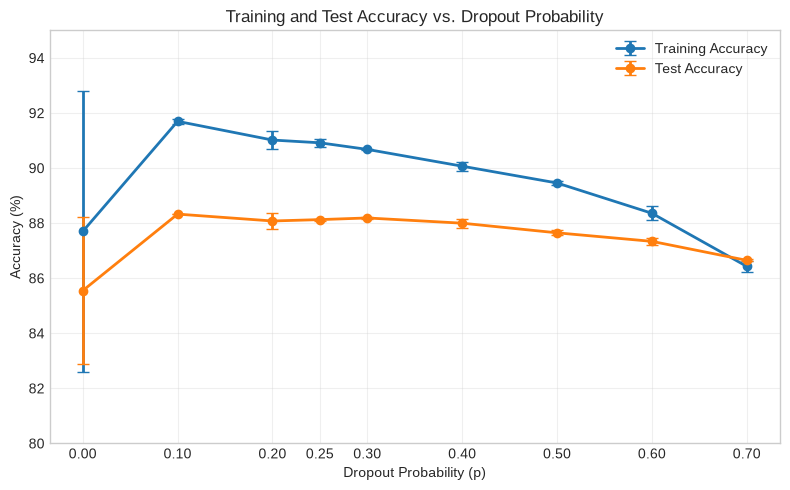

In [51]:
import numpy as np
import matplotlib.pyplot as plt

# Dropout probabilities
dropout_p = np.array([
    0.0, 0.1, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7
])

# Mean accuracy (%)
train_mean = np.array([
    87.70, 91.70, 91.02, 90.92, 90.68,
    90.07, 89.46, 88.36, 86.43
])

test_mean = np.array([
    85.55, 88.33, 88.08, 88.13, 88.19,
    88.00, 87.65, 87.34, 86.65
])

# Standard deviation (%)
train_std = np.array([
    5.11, 0.10, 0.34, 0.15, 0.01,
    0.17, 0.07, 0.25, 0.20
])

test_std = np.array([
    2.67, 0.00, 0.28, 0.04, 0.05,
    0.16, 0.09, 0.14, 0.04
])

# Create figure
plt.figure(figsize=(8, 5))

# Training accuracy
plt.errorbar(
    dropout_p,
    train_mean,
    yerr=train_std,
    marker='o',
    capsize=4,
    linewidth=2,
    label='Training Accuracy'
)

# Test accuracy
plt.errorbar(
    dropout_p,
    test_mean,
    yerr=test_std,
    marker='o',
    capsize=4,
    linewidth=2,
    label='Test Accuracy'
)

# Labels
plt.xlabel('Dropout Probability (p)')
plt.ylabel('Accuracy (%)')
plt.title('Training and Test Accuracy vs. Dropout Probability')

# Grid and legend
plt.grid(True, alpha=0.3)
plt.legend()

# X-axis
plt.xticks(dropout_p)

# Y-axis range
plt.ylim(80, 95)

# Layout
plt.tight_layout()

# Save figure
plt.savefig(
    'experiment4_dropout_train_test.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

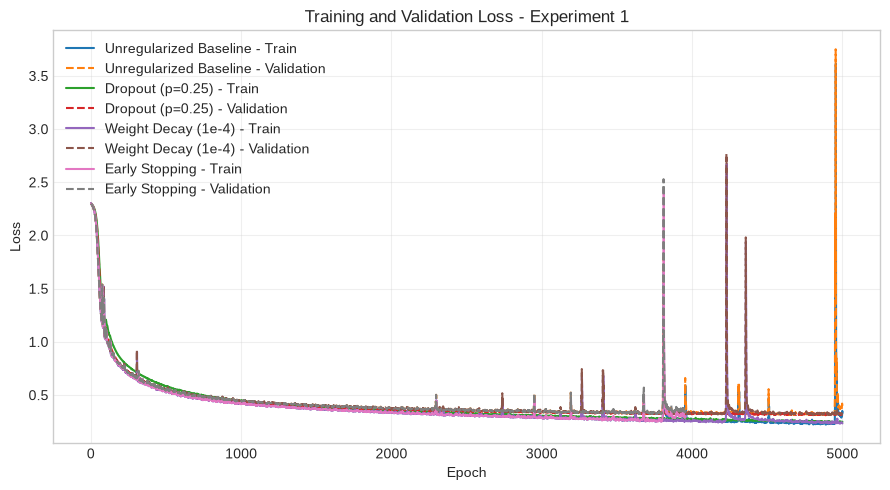

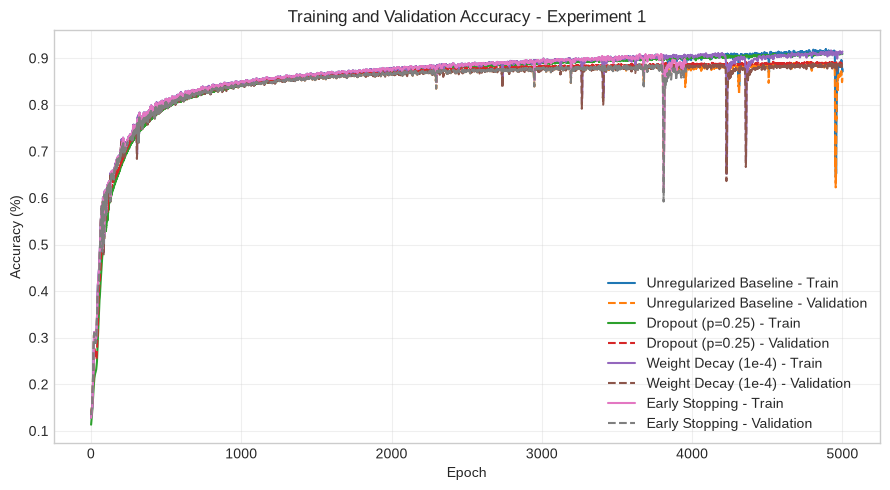

KeyError: 'Combined'

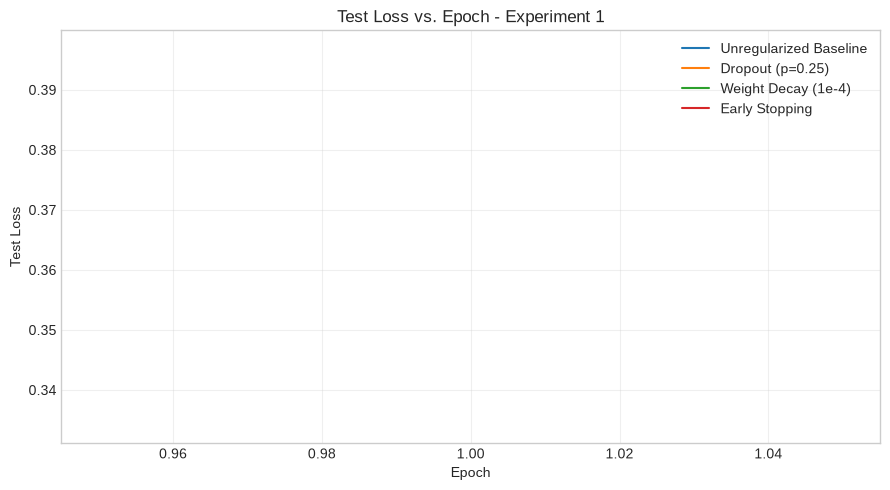

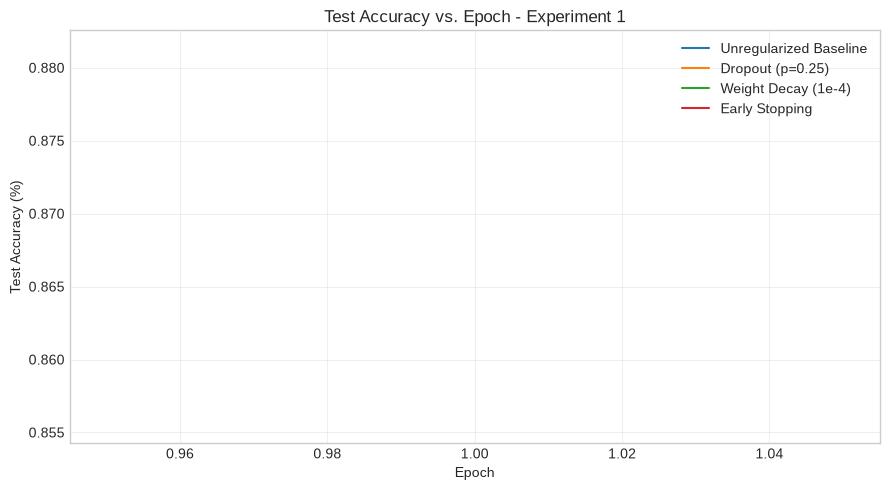

KeyError: 'Combined'

In [58]:
import numpy as np
import matplotlib.pyplot as plt


def mean_history(histories, key):
    max_len = max(len(h[key]) for h in histories)

    values = np.full((len(histories), max_len), np.nan)

    for i, h in enumerate(histories):
        values[i, :len(h[key])] = h[key]

    return np.nanmean(values, axis=0), np.nanstd(values, axis=0)


# ============================================================
# EXPERIMENT 1
# ============================================================

experiment1 = {
    'Unregularized Baseline': all_results['Unregularized Baseline'],
    'Dropout (p=0.25)': all_results['Dropout (p=0.25)'],
    'Weight Decay (1e-4)': all_results['Weight Decay (1e-4)'],
    'Early Stopping': all_results['Early Stopping']
}


# -------------------------
# TEST LOSS
# -------------------------

plt.figure(figsize=(9, 5))

for name, histories in experiment1.items():

    test_mean, test_std = mean_history(histories, 'test_loss')
    epochs = np.arange(1, len(test_mean) + 1)

    plt.plot(
        epochs,
        test_mean,
        label=name
    )

plt.xlabel('Epoch')
plt.ylabel('Test Loss')
plt.title('Test Loss vs. Epoch - Experiment 1')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    'experiment1_test_loss_convergence.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# -------------------------
# TEST ACCURACY
# -------------------------

plt.figure(figsize=(9, 5))

for name, histories in experiment1.items():

    test_mean, test_std = mean_history(histories, 'test_acc')
    epochs = np.arange(1, len(test_mean) + 1)

    plt.plot(
        epochs,
        test_mean,
        label=name
    )

plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.title('Test Accuracy vs. Epoch - Experiment 1')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    'experiment1_test_accuracy_convergence.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ============================================================
# EXPERIMENT 2
# ============================================================

experiment2 = {
    'Unregularized Baseline': all_results['Unregularized Baseline'],
    'Combined': all_results['Combined']
}


# -------------------------
# TEST LOSS
# -------------------------

plt.figure(figsize=(9, 5))

for name, histories in experiment2.items():

    test_mean, test_std = mean_history(histories, 'test_loss')
    epochs = np.arange(1, len(test_mean) + 1)

    plt.plot(
        epochs,
        test_mean,
        label=name
    )

plt.xlabel('Epoch')
plt.ylabel('Test Loss')
plt.title('Test Loss vs. Epoch - Experiment 2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    'experiment2_test_loss_convergence.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# -------------------------
# TEST ACCURACY
# -------------------------

plt.figure(figsize=(9, 5))

for name, histories in experiment2.items():

    test_mean, test_std = mean_history(histories, 'test_acc')
    epochs = np.arange(1, len(test_mean) + 1)

    plt.plot(
        epochs,
        test_mean,
        label=name
    )

plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.title('Test Accuracy vs. Epoch - Experiment 2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    'experiment2_test_accuracy_convergence.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()